# 01. Nasze nagrania z BrainAccess MINI: jakość i struktura

Pierwsza analiza czterech nagrań testowych z `data/recordings/` (Adi, Filip, Rudy, Wojtek): 8 kanałów, 250 Hz, elektrody suche. Szukamy odpowiedzi na pytania:

1. Czy pliki są poprawne (jednostki, kontakt elektrod, ciągłość próbek)?
2. Ile z nagrań nadaje się do analizy, a ile zajmują artefakty ruchu?
3. Jak wygląda widmo i szum sieciowy (50 Hz)?
4. Czy epizody alfy (zamknięte oczy) da się znaleźć z samego sygnału, bez korzystania ze znaczników protokołu?

> **Etykiety:** pierwsza wersja tego notebooka powstała, zanim nagrania dostały znaczniki. Teraz bloki protokołu (`neutral` = swobodna rozmowa, `eyes_closed`, `reading`, `math`, `control`) są w `data/recordings/*-raw_annotations.csv`. Sekcja 5 nadal celowo szuka epizodów alfy **z samego sygnału**, bez etykiet, a na końcu porównujemy je z prawdziwym blokiem `eyes_closed`. Trafność wskaźnika na etykietach liczy notebook 03.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})

OUR_CH = ["F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2"]
FS = 250
WIN_S, STEP_S = 2.0, 1.0
REJECT_UV = 300          # drop 2 s windows whose peak-to-peak exceeds this (any channel)
PERSON_COLORS = {"adi": "tab:blue", "filip": "tab:orange", "rudy": "tab:green", "wojtek": "tab:red"}


def find_recordings():
    """Locate data/recordings (repo checkout, Colab upload, or fresh clone)."""
    for p in [Path("../recordings"), Path("data/recordings"), Path("recordings"), Path("/content/recordings")]:
        if list(p.glob("*raw.fif")):
            return p
    import subprocess
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/wskalecki/Heroes_of_the_brain_AI_All_IN.git", "/content/repo"],
        capture_output=True,
    )
    p = Path("/content/repo/data/recordings")
    if list(p.glob("*raw.fif")):
        return p
    raise FileNotFoundError(
        "Nie znaleziono plików *raw.fif. Wgraj je do /content/recordings (panel plików w Colabie) "
        "albo sklonuj repo (jeśli jest prywatne, trzeba tokenu)."
    )


def load_recordings(rec_dir):
    out = {}
    for f in sorted(rec_dir.glob("*raw.fif")):
        out[f.name.split("task-")[1].split("_")[0]] = mne.io.read_raw_fif(f, preload=True)
    return out


def accel_jerk(raw):
    """Smoothed magnitude of accelerometer change (a movement proxy), one value per sample."""
    a = raw.copy().pick(["Accel_x", "Accel_y", "Accel_z"]).get_data()
    j = np.sqrt((np.diff(a, axis=1) ** 2).sum(0))
    j = np.r_[j[0], j]
    return pd.Series(j).rolling(FS, center=True, min_periods=1).mean().values


def find_end_trim(raw, factor=3.0):
    """Time (s) from which movement stays high until the end (headset being taken off)."""
    j = accel_jerk(raw)
    low = np.where(j < factor * np.median(j))[0]
    return raw.times[low[-1]] if len(low) else raw.times[-1]


def clean_windows(raw8, hp_only=False):
    """Epoch a raw (8 EEG channels) into 2 s windows with 1 s step."""
    return mne.make_fixed_length_epochs(raw8, duration=WIN_S, overlap=WIN_S - STEP_S, preload=True)


## 1. Wczytanie i podstawowa kontrola plików

In [2]:
REC = find_recordings()
raws = load_recordings(REC)

rows = []
for n, r in raws.items():
    eeg = r.copy().pick(OUR_CH).get_data()
    contact = r.copy().pick([f"contact_{c}" for c in OUR_CH]).get_data()
    batt = r.copy().pick(["Battery"]).get_data()[0]
    sample = r.copy().pick(["Sample"]).get_data()[0]
    rows.append({
        "osoba": n,
        "czas [min]": round(r.times[-1] / 60, 1),
        "fs [Hz]": r.info["sfreq"],
        "kontakt OK [%]": round((contact > 0.5).mean() * 100, 1),
        "luki w próbkach": int((np.diff(sample) != 1).sum()),
        "bateria [%]": f"{batt[0]:.0f} → {batt[-1]:.0f}",
        "adnotacje": len(r.annotations),
        "mediana DC [mV]": round(np.median(eeg) * 1e3),
        "std surowego [µV]": round(eeg.std() * 1e6),
    })
pd.DataFrame(rows).set_index("osoba")

,czas [min],fs [Hz],kontakt OK [%],luki w próbkach,bateria [%],adnotacje,mediana DC [mV],std surowego [µV]
osoba,,,,,,,,
adi,9.1,250.0,100.0,0,83 → 82,0,13,41586
filip,14.7,250.0,100.0,0,87 → 85,0,90,52885
rudy,9.1,250.0,100.0,0,85 → 84,0,107,46547
wojtek,8.5,250.0,100.0,0,81 → 80,0,119,38035


Pliki są ciągłe (zero luk w numeracji próbek), a czujnik kontaktu pokazuje stale „dobry” u wszystkich. Ta flaga jest więc w praktyce **niezawodna tylko w jedną stronę**: nie wyłapała ani jednego z dużych artefaktów widocznych niżej, więc nie można na niej polegać jako wskaźniku jakości sygnału.

**Jednostki i dryf.** Wartości w plikach są w woltach (to się zgadza z wartościami po filtrowaniu rzędu kilkudziesięciu µV). Ogromne „std surowego” wynika z powolnego dryfu składowej stałej rzędu dziesiątek do setek mV, typowego dla elektrod suchych. Dlatego **zawsze filtrujemy górnoprzepustowo od 1 Hz**, zanim cokolwiek policzymy.

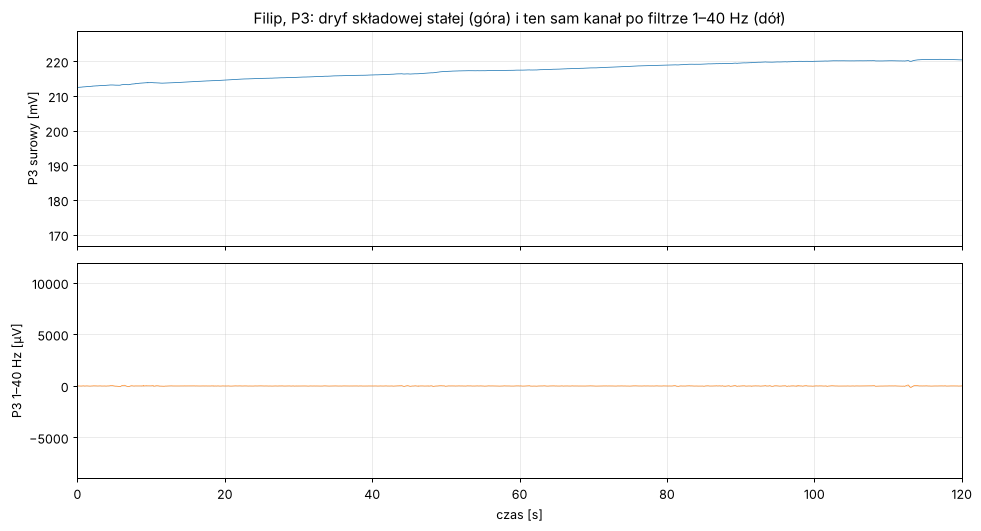

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
r = raws["filip"].copy().pick(["P3"])
t = r.times
axes[0].plot(t, r.get_data()[0] * 1e3, lw=0.6)
axes[0].set_ylabel("P3 surowy [mV]")
axes[0].set_title("Filip, P3: dryf składowej stałej (góra) i ten sam kanał po filtrze 1–40 Hz (dół)")
axes[1].plot(t, r.copy().filter(1, 40, verbose=False).get_data()[0] * 1e6, lw=0.5, color="tab:orange")
axes[1].set_ylabel("P3 1–40 Hz [µV]")
axes[1].set_xlabel("czas [s]")
axes[1].set_xlim(0, 120)
plt.tight_layout(); plt.show()

## 2. Ruch: akcelerometr i końcówka nagrań

Czapka ma akcelerometr. Na końcu każdego nagrania widać gwałtowny ruch, czyli zdejmowanie czapki. Tę końcówkę obcinamy (ostatni odcinek, w którym ruch pozostaje wysoki do końca pliku), a pozostałe fragmenty ruchu zostawiamy i oceniamy osobno.

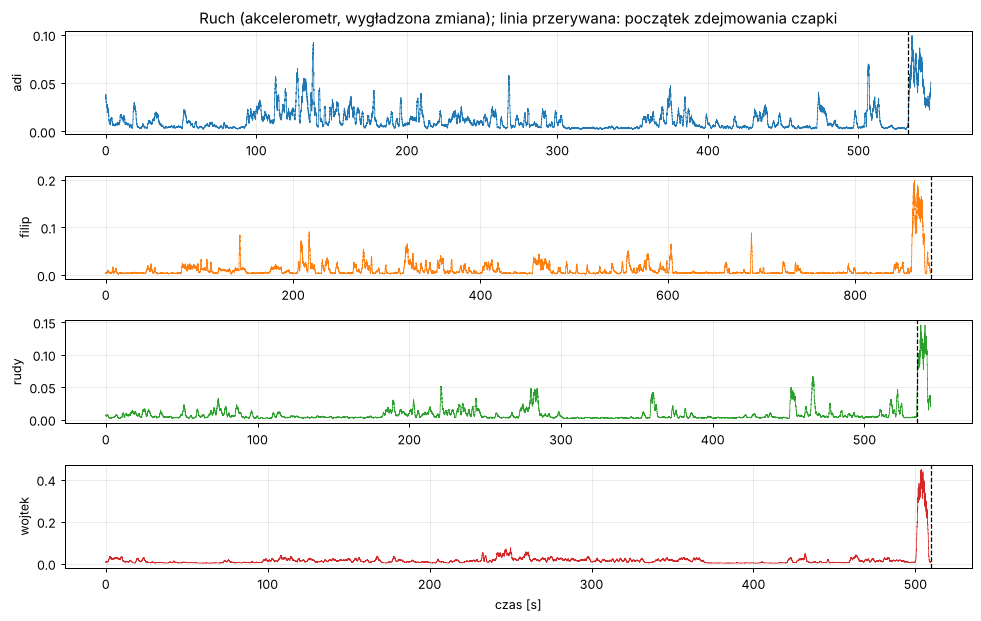

{'adi': '533 s z 548 s (obcięto 15 s)', 'filip': '881 s z 881 s (obcięto 0 s)', 'rudy': '534 s z 544 s (obcięto 9 s)', 'wojtek': '509 s z 509 s (obcięto 0 s)'}


In [4]:
trims = {n: find_end_trim(r) for n, r in raws.items()}

fig, axes = plt.subplots(4, 1, figsize=(11, 7), sharex=False)
for ax, (n, r) in zip(axes, raws.items()):
    ax.plot(r.times, accel_jerk(r), lw=0.6, color=PERSON_COLORS[n])
    ax.axvline(trims[n], color="k", ls="--", lw=1)
    ax.set_ylabel(n)
axes[0].set_title("Ruch (akcelerometr, wygładzona zmiana); linia przerywana: początek zdejmowania czapki")
axes[-1].set_xlabel("czas [s]")
plt.tight_layout(); plt.show()
print({n: f"{t:.0f} s z {raws[n].times[-1]:.0f} s (obcięto {raws[n].times[-1]-t:.0f} s)" for n, t in trims.items()})

In [5]:
eeg40, eeg_hp = {}, {}
for n, r in raws.items():
    r8 = r.copy().pick(OUR_CH)
    eeg40[n] = r8.copy().filter(1, 40, verbose=False).crop(0, trims[n])    # for band features
    eeg_hp[n] = r8.copy().filter(1, None, verbose=False).crop(0, trims[n])  # keeps 50 Hz for line-noise check

ep40 = {n: clean_windows(r) for n, r in eeg40.items()}
ep_hp = {n: clean_windows(r) for n, r in eeg_hp.items()}
ptp = {n: np.ptp(e.get_data(), axis=-1) * 1e6 for n, e in ep40.items()}   # (windows, channels), µV
bad = {n: (p > REJECT_UV).any(1) for n, p in ptp.items()}
print({n: len(b) for n, b in bad.items()}, "okien 2 s (krok 1 s)")

{'adi': 532, 'filip': 879, 'rudy': 533, 'wojtek': 508} okien 2 s (krok 1 s)


## 3. Artefakty: ile nagrania jest „czyste”

Okno 2 s uznajemy za artefakt, gdy amplituda szczyt-szczyt na dowolnym kanale przekracza 300 µV (ten sam próg co w notebooku z danymi publicznymi). Poniżej mapa amplitudy w czasie: jasne pionowe pasy na wszystkich kanałach naraz to ruch głowy, poprawianie czapki lub napięcie mięśni.

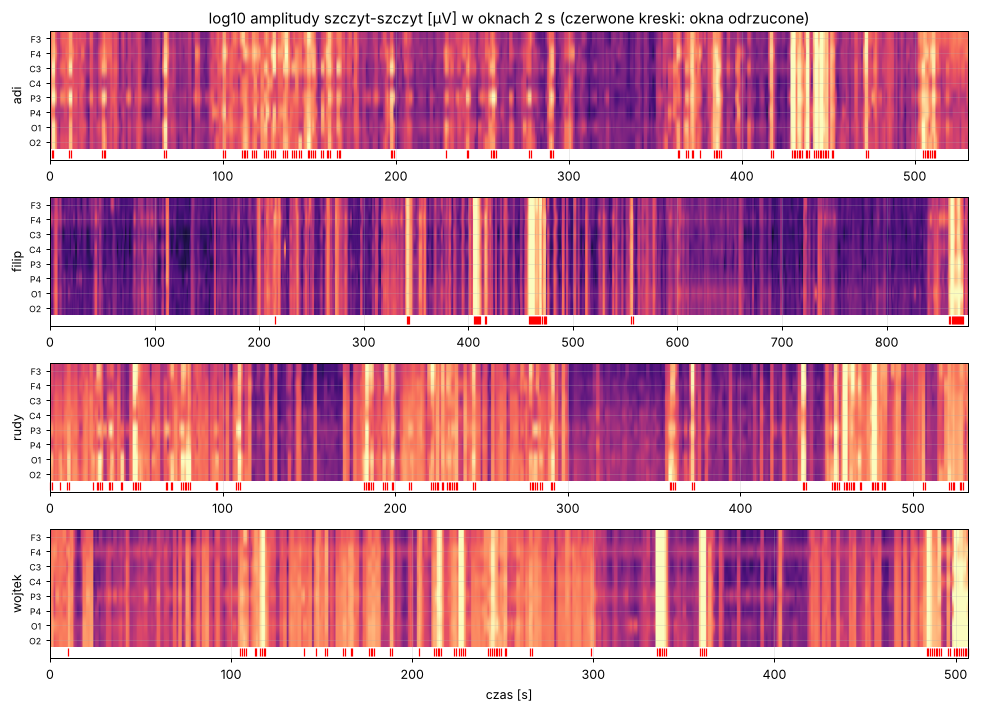

,okna,odrzucone [%],mediana p2p F3,mediana p2p F4,mediana p2p C3,mediana p2p C4,mediana p2p P3,mediana p2p P4,mediana p2p O1,mediana p2p O2
adi,532,19.7,97.0,106.0,103.0,80.0,108.0,82.0,101.0,98.0
filip,879,5.1,45.0,51.0,41.0,44.0,44.0,48.0,62.0,56.0
rudy,533,21.4,103.0,114.0,127.0,136.0,149.0,147.0,166.0,169.0
wojtek,508,15.7,104.0,128.0,132.0,142.0,156.0,147.0,163.0,156.0


In [6]:
fig, axes = plt.subplots(4, 1, figsize=(11, 8))
for ax, n in zip(axes, ptp):
    t0 = ep40[n].events[:, 0] / FS
    ax.imshow(np.log10(ptp[n].T), aspect="auto", extent=[t0[0], t0[-1], 8, 0], vmin=1, vmax=2.8, cmap="magma")
    ax.set_yticks(np.arange(8) + 0.5, OUR_CH, fontsize=7)
    ax.set_ylabel(n)
    ax.plot(t0[bad[n]], np.full(bad[n].sum(), 8.3), "|", color="red", ms=6, clip_on=False)
axes[0].set_title("log10 amplitudy szczyt-szczyt [µV] w oknach 2 s (czerwone kreski: okna odrzucone)")
axes[-1].set_xlabel("czas [s]")
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "okna": {n: len(b) for n, b in bad.items()},
    "odrzucone [%]": {n: round(b.mean() * 100, 1) for n, b in bad.items()},
}).join(pd.DataFrame({n: np.median(p, 0).round(0) for n, p in ptp.items()}, index=OUR_CH).T.add_prefix("mediana p2p ").round(0))
summary

Dwie obserwacje. **Po pierwsze**, w nagraniach jest dużo odcinków ciągłej, umiarkowanej aktywności o amplitudzie 100–200 µV szczyt-szczyt, którą próg 300 µV przepuszcza. To dużo jak na EEG (w zbiorach laboratoryjnych typowo kilkadziesiąt µV), więc czystość sygnału trzeba oceniać też z widma (niżej), a nie tylko z progu. Porównanie z danymi publicznymi jest w notebooku 02. **Po drugie**, artefakty są *wspólne dla wszystkich kanałów naraz*: to ruch i mięśnie, nie pojedyncze elektrody.

## 4. Widmo i szum sieciowy

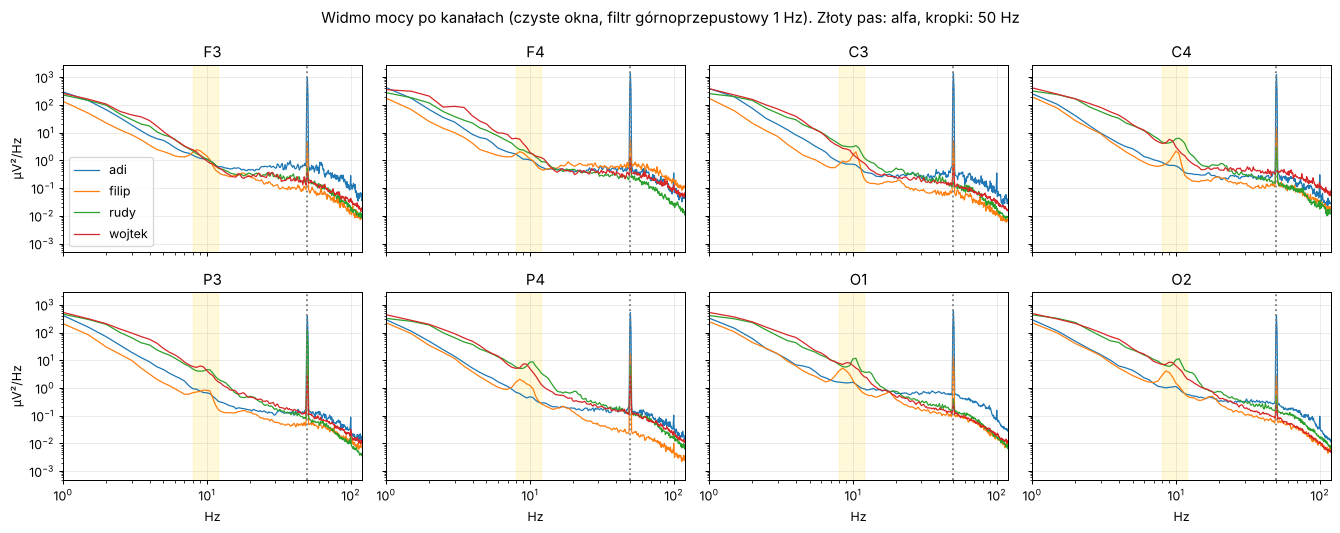

,szum sieciowy: moc 49–51 Hz względem 20–30 Hz [dB]
adi,28.8
filip,11.0
rudy,11.1
wojtek,1.6


In [7]:
from scipy.signal import welch


def mean_psd(ep, mask):
    """Mean PSD [µV²/Hz] per channel over non-rejected windows."""
    x = ep.get_data()[~mask]
    f, p = welch(x, FS, nperseg=int(WIN_S * FS), axis=-1)
    return f, p.mean(0) * 1e12


psd = {n: mean_psd(ep_hp[n], bad[n]) for n in ep_hp}
f = psd["adi"][0]

fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True, sharey=True)
for i, ch in enumerate(OUR_CH):
    ax = axes.flat[i]
    for n in psd:
        ax.loglog(f[1:], psd[n][1][i][1:], color=PERSON_COLORS[n], label=n, lw=1)
    ax.axvspan(8, 12, color="gold", alpha=0.15)
    ax.axvline(50, color="gray", ls=":")
    ax.set_title(ch)
    ax.set_xlim(1, 120)
for ax in axes[1]:
    ax.set_xlabel("Hz")
for ax in axes[:, 0]:
    ax.set_ylabel("µV²/Hz")
axes[0, 0].legend()
plt.suptitle("Widmo mocy po kanałach (czyste okna, filtr górnoprzepustowy 1 Hz). Złoty pas: alfa, kropki: 50 Hz")
plt.tight_layout(); plt.show()

line = {}
for n in psd:
    p = psd[n][1].mean(0)
    line[n] = 10 * np.log10(p[(f >= 49) & (f <= 51)].mean() / p[(f >= 20) & (f <= 30)].mean())
pd.Series(line, name="szum sieciowy: moc 49–51 Hz względem 20–30 Hz [dB]").round(1).to_frame()

Szum sieciowy 50 Hz różni się o rzędy wielkości między nagraniami. To cecha **środowiska** (zasilacze, kable, uziemienie, odległość od laptopa), a nie osoby. Filtr 1–40 Hz go usuwa z naszych cech, więc nie psuje analizy pasm theta, alfa i beta, ale silny szum sieciowy bywa objawem słabego kontaktu elektrody odniesienia, co pogarsza wszystkie kanały.

## 5. Czy w nagraniach widać epizody alfy?

Spektrogram kanałów potylicznych (O1/O2) z zaznaczonym pasmem alfa. Jeśli ktoś zamykał oczy, powinien się pojawić wyraźny pas około 8–12 Hz.

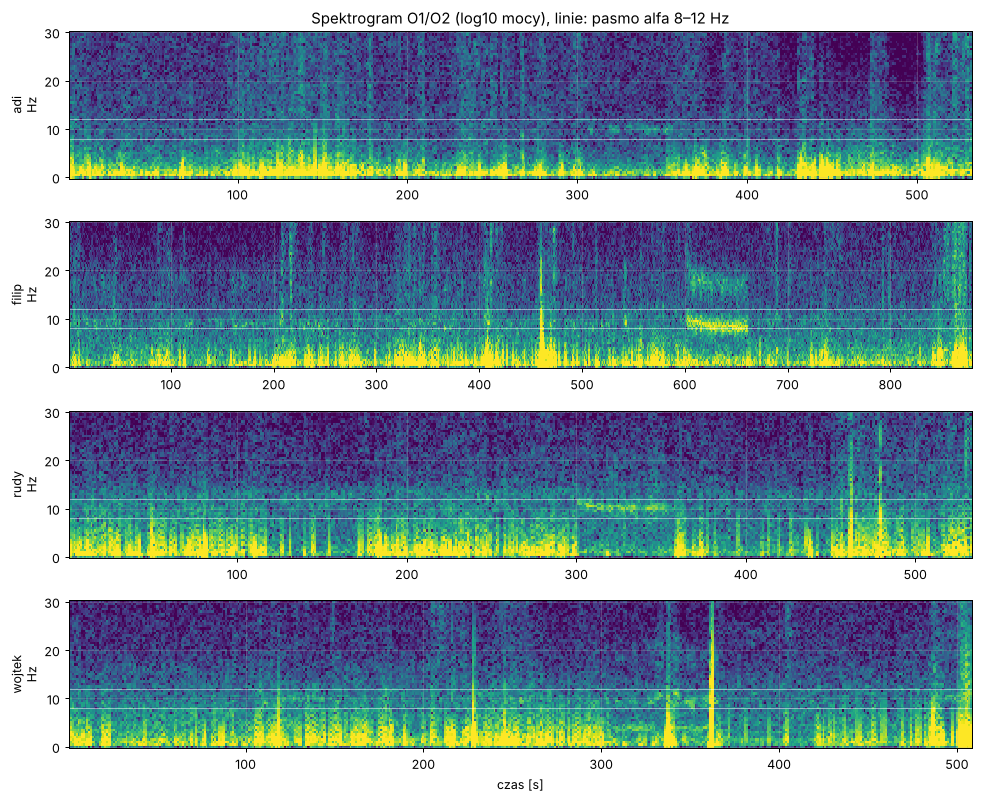

In [8]:
from scipy.signal import spectrogram

fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=False)
for ax, n in zip(axes, eeg40):
    y = eeg40[n].get_data()[[6, 7]] * 1e6
    fr, t, S = spectrogram(y, FS, nperseg=500, noverlap=250)
    S = np.log10(S.mean(0) + 1e-12)
    m = fr <= 30
    ax.pcolormesh(t, fr[m], S[m], shading="auto", vmin=np.percentile(S[m], 5), vmax=np.percentile(S[m], 97))
    ax.axhline(8, color="w", lw=0.4); ax.axhline(12, color="w", lw=0.4)
    ax.set_ylabel(f"{n}\nHz")
axes[0].set_title("Spektrogram O1/O2 (log10 mocy), linie: pasmo alfa 8–12 Hz")
axes[-1].set_xlabel("czas [s]")
plt.tight_layout(); plt.show()

### Automatyczne wykrywanie epizodów alfy

Dla każdego okna liczymy „wyrazistość alfy” na O1/O2: stosunek mocy w 8–12 Hz do mocy w sąsiednich pasmach (5–7 Hz i 14–16 Hz, średnia geometryczna). Dzięki temu nachylenie 1/f nie udaje alfy. Potem normalizujemy w obrębie osoby (mediana i MAD z czystych okien), wygładzamy po 5 oknach i szukamy ciągłych odcinków powyżej progu.

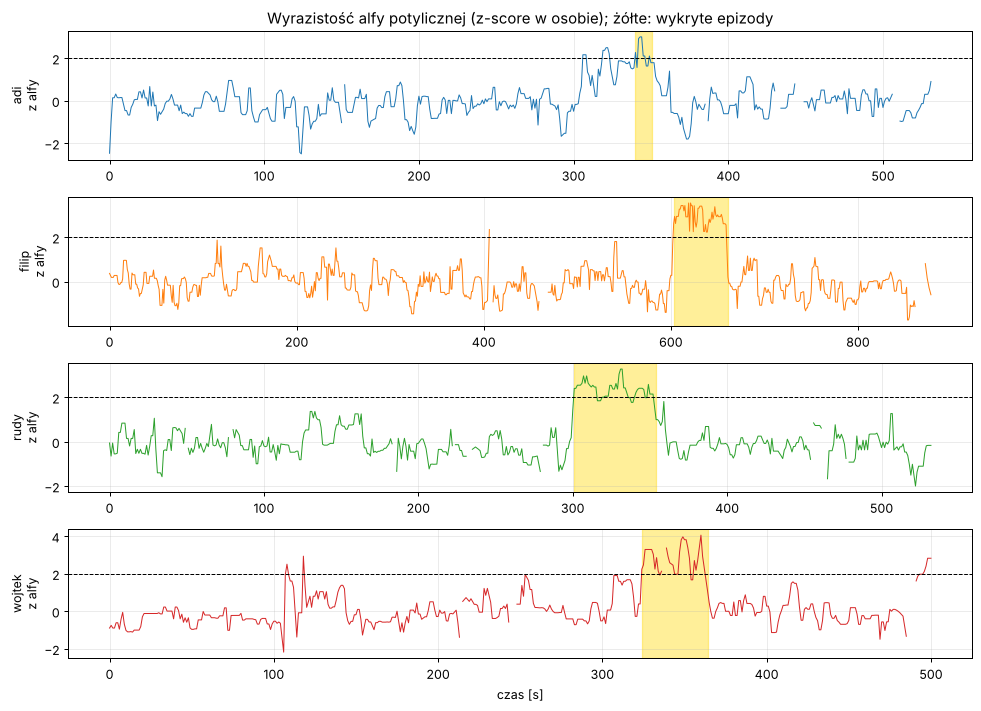

,osoba,start [s],koniec [s],długość [s]
0,adi,340,351,11
1,filip,603,661,58
2,rudy,301,354,53
3,wojtek,324,364,40


In [9]:
from scipy.ndimage import binary_closing

Z_THR, MIN_LEN_S = 2.0, 8


def alpha_prominence(ep, mask):
    x = ep.get_data()[:, [6, 7]]                      # O1, O2
    f, p = welch(x, FS, nperseg=int(WIN_S * FS), axis=-1)
    p = p.mean(1)                                     # average the two channels
    band = lambda lo, hi: p[:, (f >= lo) & (f <= hi)].mean(1)
    prom = np.log10(band(8, 12) / np.sqrt(band(5, 7) * band(14, 16)))
    prom = np.where(mask, np.nan, prom)
    med = np.nanmedian(prom)
    mad = np.nanmedian(np.abs(prom - med)) * 1.4826
    z = (prom - med) / mad
    return pd.Series(z).rolling(5, center=True, min_periods=1).median().values


def find_episodes(z, t0):
    on = np.nan_to_num(z, nan=-9) > Z_THR
    on = binary_closing(on, structure=np.ones(5, bool))   # bridge gaps up to 4 s (e.g. rejected windows)
    eps, start = [], None
    for i, v in enumerate(np.r_[on, False]):
        if v and start is None:
            start = i
        if not v and start is not None:
            if t0[min(i, len(t0) - 1)] - t0[start] >= MIN_LEN_S:
                eps.append((t0[start], t0[i - 1] + WIN_S))
            start = None
    return eps


zalpha, episodes = {}, {}
for n in ep40:
    t0 = ep40[n].events[:, 0] / FS
    zalpha[n] = alpha_prominence(ep40[n], bad[n])
    episodes[n] = find_episodes(zalpha[n], t0)

fig, axes = plt.subplots(4, 1, figsize=(11, 8))
for ax, n in zip(axes, zalpha):
    t0 = ep40[n].events[:, 0] / FS
    ax.plot(t0, zalpha[n], lw=0.8, color=PERSON_COLORS[n])
    ax.axhline(Z_THR, color="k", ls="--", lw=0.8)
    for a, b in episodes[n]:
        ax.axvspan(a, b, color="gold", alpha=0.4)
    ax.set_ylabel(f"{n}\nz alfy")
axes[0].set_title("Wyrazistość alfy potylicznej (z-score w osobie); żółte: wykryte epizody")
axes[-1].set_xlabel("czas [s]")
plt.tight_layout(); plt.show()

ep_table = pd.DataFrame(
    [(n, round(a), round(b), round(b - a)) for n, es in episodes.items() for a, b in es],
    columns=["osoba", "start [s]", "koniec [s]", "długość [s]"],
)
ep_table.to_csv("alpha-episodes.csv", index=False)   # reused by notebook 02
ep_table if len(ep_table) else "brak epizodów"

### Widmo w epizodach alfy a poza nimi (O1/O2)

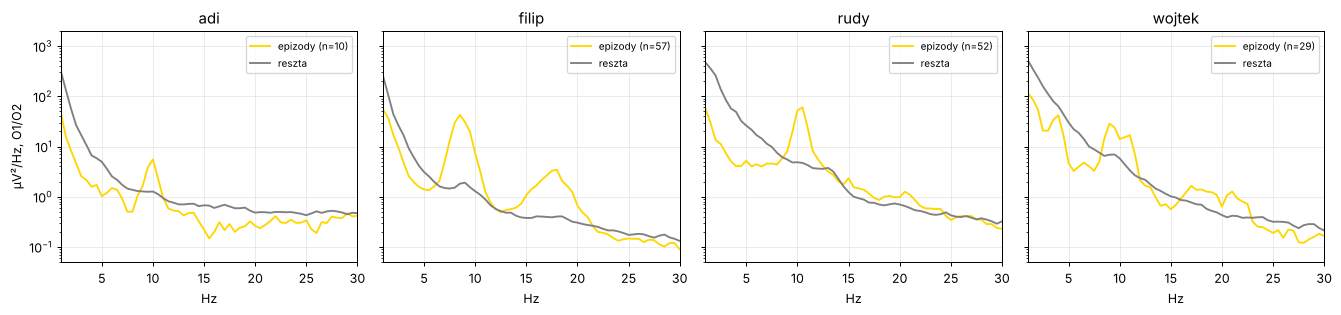

Częstotliwość szczytu alfy w epizodach [Hz]: {'adi': np.float64(10.0), 'filip': np.float64(8.5), 'rudy': np.float64(10.5), 'wojtek': np.float64(9.0)}


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
peak = {}
for ax, n in zip(axes, ep40):
    t0 = ep40[n].events[:, 0] / FS
    inside = np.zeros(len(t0), bool)
    for a, b in episodes[n]:
        inside |= (t0 >= a) & (t0 + WIN_S <= b)
    x = ep40[n].get_data()[:, [6, 7]]
    fr, p = welch(x, FS, nperseg=int(WIN_S * FS), axis=-1)
    p = p.mean(1) * 1e12
    ok = ~bad[n]
    if (inside & ok).any():
        ax.semilogy(fr, p[inside & ok].mean(0), label=f"epizody (n={int((inside & ok).sum())})", color="gold")
        m = (fr >= 7) & (fr <= 13)
        peak[n] = fr[m][np.argmax(p[inside & ok].mean(0)[m])]
    ax.semilogy(fr, p[~inside & ok].mean(0), label="reszta", color="gray")
    ax.set_xlim(1, 30); ax.set_ylim(0.05, 2e3); ax.set_title(n); ax.set_xlabel("Hz"); ax.legend(fontsize=8)
axes[0].set_ylabel("µV²/Hz, O1/O2")
plt.tight_layout(); plt.show()
print("Częstotliwość szczytu alfy w epizodach [Hz]:", peak)

## 6. Epizody a prawdziwe etykiety

Epizody powyżej wykryliśmy bez etykiet. Teraz porównujemy je z blokiem `eyes_closed` z pliku adnotacji każdego nagrania.

In [11]:
labels = {f.name.split("task-")[1].split("_")[0]: pd.read_csv(f) for f in sorted(REC.glob("*raw_annotations.csv"))}
rows = []
for n, L in labels.items():
    ec = L[L.description == "eyes_closed"].iloc[0]
    e0, e1 = ec.onset, ec.onset + ec.duration
    for a, b in episodes.get(n, []):
        ov = max(0.0, min(b, e1) - max(a, e0))
        rows.append({"osoba": n, "epizod": f"{a:.0f}–{b:.0f} s", "eyes_closed": f"{e0:.0f}–{e1:.0f} s",
                     "epizodu w bloku [%]": 100 * ov / (b - a), "pokrycie bloku [%]": 100 * ov / (e1 - e0),
                     "start po początku bloku [s]": a - e0})
pd.DataFrame(rows).set_index("osoba").round(0)

,epizod,eyes_closed,epizodu w bloku [%],pokrycie bloku [%],start po początku bloku [s]
osoba,,,,,
adi,340–351 s,300–360 s,100.0,18.0,40.0
filip,603–661 s,600–660 s,98.0,95.0,3.0
rudy,301–354 s,300–360 s,100.0,88.0,1.0
wojtek,324–364 s,300–363 s,98.0,62.0,24.0


## Wnioski

- **Pliki są poprawne i ciągłe** (zero luk w próbkach, 250 Hz), ale flaga kontaktu elektrod stale pokazuje „dobry” (100%), także podczas dużych artefaktów. Nie nadaje się jako miara jakości sygnału.
- **Sygnał ma duży dryf składowej stałej** (dziesiątki do setek mV). Filtr górnoprzepustowy od 1 Hz jest konieczny przed jakąkolwiek analizą.
- **Artefakty ruchu są częste.** Próg 300 µV odrzuca 5% okien u Filipa i 16–21% u pozostałych. Mediana amplitudy okna to 80–170 µV u Adiego, Rudy'ego i Wojtka oraz 40–60 µV u Filipa. Artefakty występują na wszystkich kanałach naraz, więc to ruch i mięśnie, a nie pojedyncze elektrody.
- **Szum sieciowy zależy od sesji:** +29 dB (Adi), +11 dB (Filip, Rudy) i +2 dB (Wojtek) względem pasma 20–30 Hz. Filtr 1–40 Hz go usuwa z cech, ale warto sprawdzić uziemienie i kable w nagraniu Adiego.
- **W każdym nagraniu jest jeden wyraźny epizod alfy** z pikiem 8,5–10,5 Hz: Adi 340–351 s, Filip 603–661 s, Rudy 301–354 s, Wojtek 324–364 s. U Filipa widać też drugi garb około 18 Hz, czyli harmoniczną alfy. **Etykiety to potwierdzają:** każdy epizod leży w bloku `eyes_closed` (98–100% długości epizodu), poza blokiem nie ma żadnego epizodu. Epizody są jednak krótsze niż blok: pokrywają 18% (Adi), 95% (Filip), 88% (Rudy) i 62% (Wojtek) czasu z zamkniętymi oczami. U Adiego i Wojtka alfa przy zamkniętych oczach jest słabsza i zaczyna się 40 s i 24 s po początku bloku (tabela w sekcji 6).
- **Trafność detektora na etykietach** (czułość, fałszywe alarmy, AUC, opóźnienie, kalibracja) jest policzona w notebooku 03.